# Wonders of the World - Image Classification

### Project Description

Build a Convolutional Neural Network (CNN) to classify images of 12 famous wonders of the world:
- Burj Khalifa 🏙️
- Chichen Itza 🏯
- Christ the Redeemer ✝️
- Eiffel Tower 🗼
- Great Wall of China 🏯
- Machu Picchu 🏔️
- Pyramids of Giza 🏜️
- Roman Colosseum 🏟️
- Statue of Liberty 🗽
- Stonehenge 🪨
- Taj Mahal 🕌
- Venezuela Angel Falls 🌊

In [32]:
import tensorflow as tf
tf.__version__

'2.16.1'

# Splitting dataset with `splitfolders` 

In [18]:
import os
import splitfolders
import shutil
import pathlib
import numpy as np

In [19]:
RANDOM_SEED = 42

In [6]:
!pip install split-folders[full]


[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
input_path = r"C:\Users\anug2\Downloads\CV Project Assignment\Wonders of World\Wonders of World"
output_path = r"C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted"

# Split into train (80%) and val (20%)
splitfolders.ratio(input_path, output=output_path,
                   seed=RANDOM_SEED, ratio=(.8, .2),
                   group_prefix=None, move=False)

Copying files: 3846 files [00:09, 421.03 files/s]


In [21]:
shutil.rmtree(os.path.join(output_path, "val", "Wonders of World"), ignore_errors=True)
shutil.rmtree(os.path.join(output_path, "train", "Wonders of World"), ignore_errors=True)

# Checking out how many labels and image files have the dataset

In [22]:
def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

walk_through_dir(output_path)

There are 2 directories and 0 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted'.
There are 12 directories and 0 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train'.
There are 0 directories and 312 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\burj_khalifa'.
There are 0 directories and 272 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\chichen_itza'.
There are 0 directories and 258 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\christ_the_reedemer'.
There are 0 directories and 312 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\eiffel_tower'.
There are 0 directories and 313 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\great_wall_of_china'.
There are 0 directories and 314 images in 'C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\machu_pichu'

# Getting the class names (labels) dynamically

In [27]:
def get_class_name_from_dataset(target_dir: str):
    """Get list of class names or labels for image classification."""
    if not target_dir:
        print("Please provide a directory path!")
        return
    if not os.path.isdir(target_dir):
        print("This directory path does not exist!")
        return

    data_dir = pathlib.Path(target_dir)
    class_names = np.array(sorted([item.name for item in data_dir.glob("*") if item.is_dir()])).tolist()
    return class_names

train_dir = os.path.join(output_path, "train")
class_names = get_class_name_from_dataset(train_dir)
print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['burj_khalifa', 'chichen_itza', 'christ_the_reedemer', 'eiffel_tower', 'great_wall_of_china', 'machu_pichu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty', 'stonehenge', 'taj_mahal', 'venezuela_angel_falls']
Number of classes: 12


# Set hyperparameters

In [28]:
BATCH_SIZE = 32
EPOCHS = 5
IMAGE_SIZE = (400, 400)
LABEL_MODE = "categorical"
AUGMENTATION_FACTOR = 0.2

TRAIN_DIR = train_dir
TEST_DIR = os.path.join(output_path, "val")

print("\nTrain Directory:", TRAIN_DIR)
print("Validation Directory:", TEST_DIR)


Train Directory: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train
Validation Directory: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\val


# Checking out the images randomly

Image shape: (1365, 2048, 3)


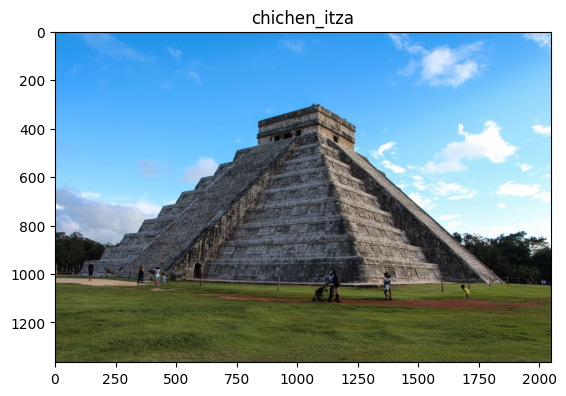

In [29]:
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def show_random_image_from_dataset(target_dir, class_names):
    if not target_dir:
        print("Please path a directory!")
        return

    if not os.path.isdir(target_dir):
        print("This directory path does not exist!")
        return
    
    # Setup target directory (we'll view images from here)
    target_class = random.choice(class_names)
    target_folder: str = target_dir + target_class

    # Get a random image path
    random_image = random.sample(os.listdir(target_folder), 1)

    # Read in the image and plot it using matplotlib
    img = mpimg.imread(target_folder + "/" + random_image[0])
    plt.imshow(img)
    plt.title(target_class)

    print(f"Image shape: {img.shape}") # show the shape of the image

show_random_image_from_dataset(target_dir=f"{TRAIN_DIR}/", class_names=class_names)

# Preprocessing data

In [33]:
print("training data 🧠:")
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    directory=TRAIN_DIR,
    batch_size=BATCH_SIZE,
    label_mode=LABEL_MODE,
    image_size=IMAGE_SIZE,
    seed=RANDOM_SEED,
    shuffle=True
)

print("test data 🧪:")
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    directory=TEST_DIR,
    batch_size=BATCH_SIZE,
    label_mode=LABEL_MODE,
    image_size=IMAGE_SIZE,
    seed=RANDOM_SEED,
    shuffle=False
)

training data 🧠:
Found 3072 files belonging to 12 classes.
test data 🧪:
Found 774 files belonging to 12 classes.


# Getting the class_names (labels) from the train_data object

In [34]:
class_names = train_data.class_names
class_names, len(class_names), len(test_data.class_names)

(['burj_khalifa',
  'chichen_itza',
  'christ_the_reedemer',
  'eiffel_tower',
  'great_wall_of_china',
  'machu_pichu',
  'pyramids_of_giza',
  'roman_colosseum',
  'statue_of_liberty',
  'stonehenge',
  'taj_mahal',
  'venezuela_angel_falls'],
 12,
 12)

# Data Augmentation layer

In [35]:
from tensorflow.keras.layers import Dense, RandomFlip, RandomRotation, RandomZoom, RandomHeight, RandomWidth, Rescaling
from tensorflow.keras import Sequential
from tensorflow.keras.activations import softmax

In [36]:
augmentaion_layer = Sequential([
    RandomFlip("horizontal", seed=RANDOM_SEED),
    RandomRotation(AUGMENTATION_FACTOR, seed=RANDOM_SEED),
    RandomZoom(AUGMENTATION_FACTOR, seed=RANDOM_SEED),
    RandomHeight(AUGMENTATION_FACTOR, seed=RANDOM_SEED),
    RandomWidth(AUGMENTATION_FACTOR, seed=RANDOM_SEED),
    Rescaling(1/255.)
])
augmentaion_layer

<Sequential name=sequential, built=False>

# Visualization of augmentation layer

Original image path: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\train\machu_pichu\aa6297cdc8.jpg


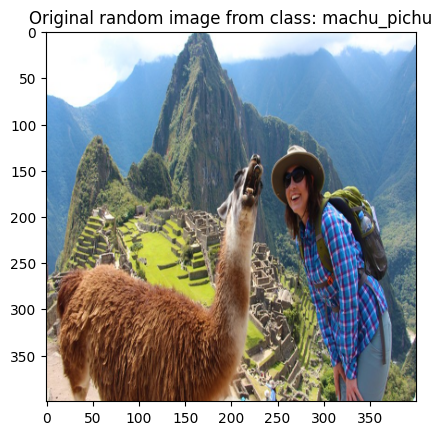

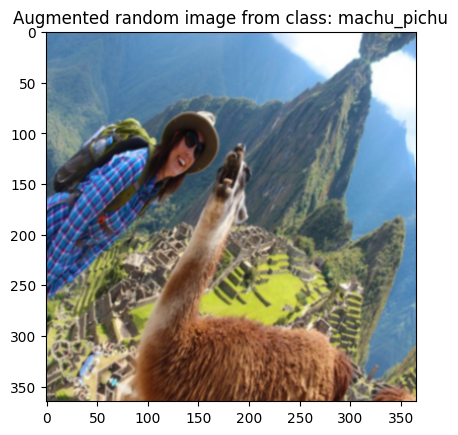

In [39]:
def show_image_after_augmentation_layer(target_dir, class_names, augmentation_layer, scale=True):
    """Display a random image and its augmented version."""

    target_class = random.choice(class_names)
    class_path = os.path.join(target_dir, target_class)
    random_image = random.choice(os.listdir(class_path))
    random_image_path = os.path.join(class_path, random_image)

    print("Original image path:", random_image_path)

    # Read the image
    img = mpimg.imread(random_image_path)

    # Resize to match augmentation layer input
    img_resized = tf.image.resize(img, IMAGE_SIZE)

    # Add batch dimension
    img_batch = tf.expand_dims(img_resized, axis=0)  # shape: (1, 400, 400, 3)

    # Show original image
    plt.figure()
    plt.title(f"Original random image from class: {target_class}")
    plt.imshow(img_resized / 255)  # normalize for display

    # Apply augmentation
    augmented_image = augmentation_layer(img_batch, training=True)

    # Remove batch dimension for plotting
    augmented_image = tf.squeeze(augmented_image, axis=0)

    plt.figure()
    plt.title(f"Augmented random image from class: {target_class}")
    if scale:
        plt.imshow(augmented_image)
    else:
        plt.imshow(augmented_image)

    plt.show()

show_image_after_augmentation_layer(target_dir=TRAIN_DIR, class_names=class_names, augmentation_layer=augmentaion_layer, scale=False)

# Create base model (Backbone)

In [40]:
base_model = tf.keras.applications.ResNet50V2(include_top=False)
base_model.trainable = False

input_layer = tf.keras.layers.Input(shape=IMAGE_SIZE + (3,), name="input_layer")
x = augmentaion_layer(input_layer)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
output_layer = Dense(len(class_names), activation=softmax, name="output_layer")(x)

model_1 = tf.keras.Model(input_layer, output_layer)


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 24s 0us/step


In [41]:
model_1.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"]
)

In [43]:
model_checkpoint_path = "checkpoint/checkpoint.weights.h5"

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_checkpoint_path,
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

In [44]:
import datetime
def create_tensorboard_callback(dir_name, experiment_name):
    """
    Creates a TensorBoard callback instand to store log files.

    Stores log files with the filepath:
      "dir_name/experiment_name/current_datetime/"

    Args:
      dir_name: target directory to store TensorBoard log files
      experiment_name: name of experiment directory (e.g. efficientnet_model_1)
    """
    log_dir = dir_name + "/" + experiment_name + "/" + \
        datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(
        log_dir=log_dir
    )
    print(f"Saving TensorBoard log files to: {log_dir}")
    return tensorboard_callback


In [46]:
# Make directory if it doesn't exist
os.makedirs("history", exist_ok=True)

# Create an empty CSV file
with open("history/history.csv", "w") as f:
    f.write("")  # write empty content

In [47]:
model_1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 400, 400, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, None, None, 3)       │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50v2 (Functional)              │ (None, None, None, 2048)    │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 12)                  │          24,588 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,589,388 (89.99 MB)

 Trainable params: 24,588 (96.05 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

# Fitting the model 

Then the model evalute all the test data

In [49]:
history_path = r"C:\Users\anug2\Downloads\CV Project Assignment\history\history.csv"

os.makedirs(os.path.dirname(history_path), exist_ok=True)

history_1 = model_1.fit(
    train_data,
    epochs=EPOCHS,
    steps_per_epoch=len(train_data),
    validation_data=test_data,
    validation_steps=int(0.15 * len(test_data)),
    callbacks=[
        tf.keras.callbacks.CSVLogger(history_path),
        checkpoint_callback,
        create_tensorboard_callback(dir_name="tensorboard", experiment_name="wonders")
    ]
)

Saving TensorBoard log files to: tensorboard/wonders/20251028-090634
Epoch 1/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.5099 - loss: 1.6113
Epoch 1: val_accuracy improved from None to 0.67708, saving model to checkpoint/checkpoint.weights.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 696s 7s/step - accuracy: 0.6953 - loss: 1.1020 - val_accuracy: 0.6771 - val_loss: 0.9095
Epoch 2/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8806 - loss: 0.4943
Epoch 2: val_accuracy improved from 0.67708 to 0.83333, saving model to checkpoint/checkpoint.weights.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 661s 7s/step - accuracy: 0.8887 - loss: 0.4539 - val_accuracy: 0.8333 - val_loss: 0.5785
Epoch 3/5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9038 - loss: 0.3550
Epoch 3: val_accuracy improved from 0.83333 to 0.95833, saving model to checkpoint/checkpoint.weights.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 661s 7s/step - accuracy: 0.9131 - loss: 0.3391 - val_accuracy: 0.9583 - val_loss: 0.2728
Epoch 4/5
96/96 ━━━━━━━━━

In [50]:
eval_1 = model_1.evaluate(test_data)
eval_1

25/25 ━━━━━━━━━━━━━━━━━━━━ 123s 5s/step - accuracy: 0.9561 - loss: 0.1978


[0.19776658713817596, 0.9560723304748535]

In [52]:
model_1.save("wonders_model.keras")

# Plot training vs validation accuracy and loss

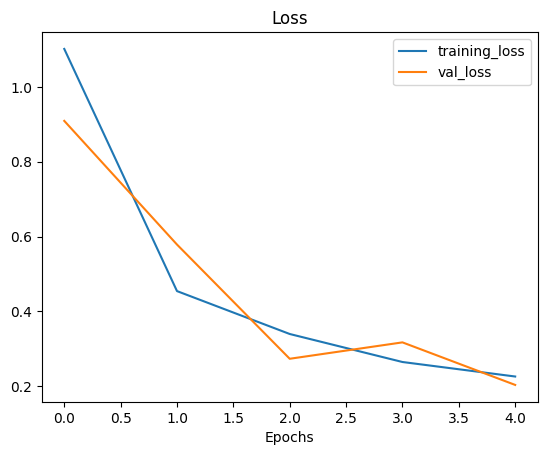

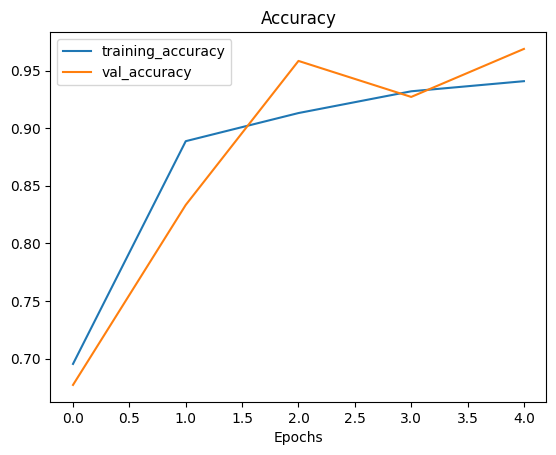

In [53]:
def plot_loss_curves(history, metric="accuracy"):
    """
    Returns separate loss curves for training and validation metrics.

    Args:
      history: TensorFlow model History object (see: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/History)
    """
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    accuracy = history.history[metric]
    val_accuracy = history.history[f"val_{metric}"]

    epochs = range(len(history.history['loss']))

    # Plot loss
    plt.plot(epochs, loss, label='training_loss')
    plt.plot(epochs, val_loss, label='val_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.figure()
    plt.plot(epochs, accuracy, label='training_accuracy')
    plt.plot(epochs, val_accuracy, label='val_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend()

plot_loss_curves(history=history_1)

#  Evaluation using confusion matrix, precision, recall, F1-score, and overall accuracy

In [54]:
len(class_names), class_names


(12,
 ['burj_khalifa',
  'chichen_itza',
  'christ_the_reedemer',
  'eiffel_tower',
  'great_wall_of_china',
  'machu_pichu',
  'pyramids_of_giza',
  'roman_colosseum',
  'statue_of_liberty',
  'stonehenge',
  'taj_mahal',
  'venezuela_angel_falls'])

In [55]:
# Make predictions with model
preds_probs = model_1.predict(test_data)
preds_probs

25/25 ━━━━━━━━━━━━━━━━━━━━ 121s 5s/step


array([[9.15142894e-01, 9.23254935e-04, 1.07908417e-02, ...,
        4.29289576e-05, 2.55220626e-02, 2.81406647e-05],
       [7.66438723e-01, 8.68319906e-03, 1.48203662e-02, ...,
        7.38433737e-04, 5.98375686e-02, 1.26828716e-04],
       [9.38809574e-01, 3.57921072e-03, 3.27162258e-03, ...,
        5.72854733e-05, 7.92880077e-03, 6.61343984e-06],
       ...,
       [2.13678468e-05, 2.05779844e-03, 5.58785768e-03, ...,
        7.71720777e-04, 1.02891245e-05, 9.52962220e-01],
       [6.66230990e-05, 5.75870683e-04, 8.78183451e-03, ...,
        4.52259883e-05, 5.82634448e-06, 9.66423452e-01],
       [1.48966574e-04, 8.71044304e-03, 3.26202139e-02, ...,
        1.24821556e-04, 1.03622202e-04, 7.54178345e-01]], dtype=float32)

In [56]:
# Get the pred classes of each label
pred_classes = preds_probs.argmax(axis=1)
pred_classes[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int64)

In [57]:
def get_predicted_labels_from_test_data(test_data):
    """return real labels (or y labels) from test_data (test_data must be BatchDataset)

    Args:
        test_data (Any): test data

    Returns:
        _type_: currently test labels look like: [0, 0, 0, 1, .... 0, 0], we want the index value where the "1" occurs
    """
    y_labels = []
    for images, labels in test_data.unbatch():
        y_labels.append(labels.numpy().argmax())
    return y_labels

y_labels = get_predicted_labels_from_test_data(test_data=test_data)
y_labels[:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [58]:
# Let's try scikit-learn's accuracy score function and see what it comes up with
from sklearn.metrics import accuracy_score
sklearn_accuracy = accuracy_score(y_true=y_labels,
                                  y_pred=pred_classes)
sklearn_accuracy

0.9560723514211886

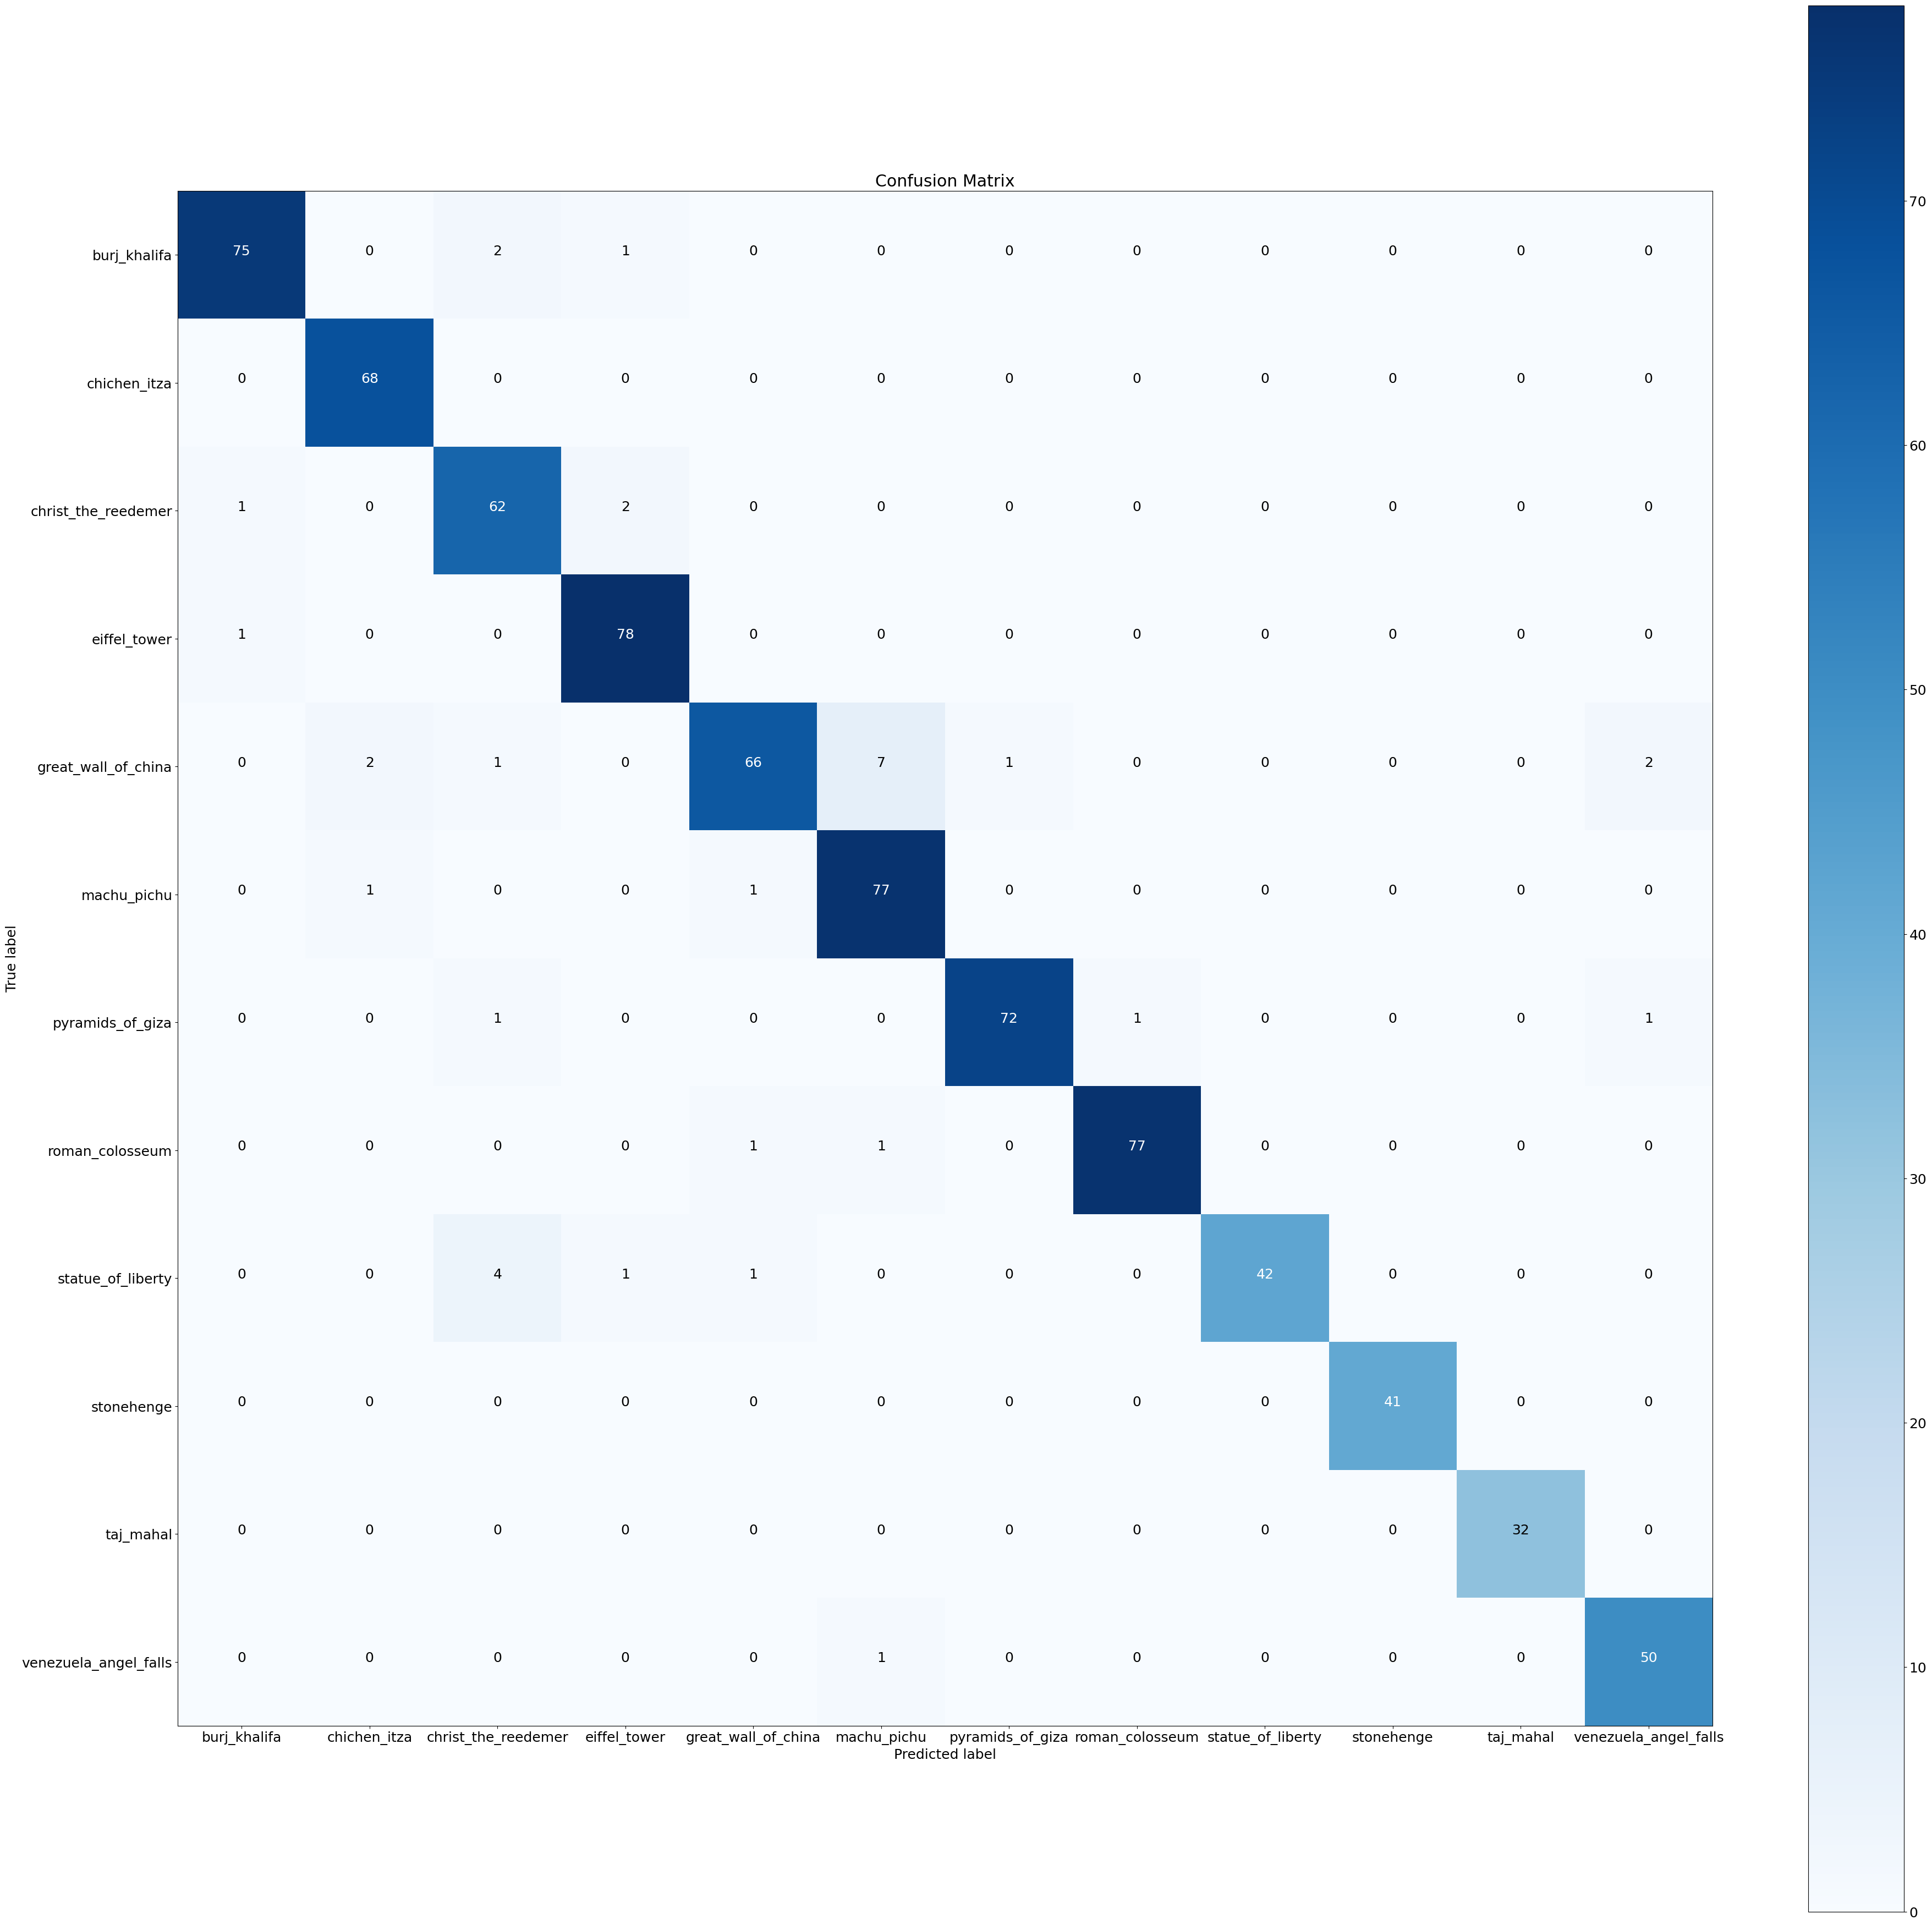

In [59]:
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib

def make_confusion_matrix(y_true, y_pred, classes=None, figsize=(10, 10), text_size=15, norm=False, savefig=False):
    """Makes a labelled confusion matrix comparing predictions and ground truth labels.

    If classes is passed, confusion matrix will be labelled, if not, integer class values
    will be used.

    Args:
      y_true: Array of truth labels (must be same shape as y_pred).
      y_pred: Array of predicted labels (must be same shape as y_true).
      classes: Array of class labels (e.g. string form). If `None`, integer labels are used.
      figsize: Size of output figure (default=(10, 10)).
      text_size: Size of output figure text (default=15).
      norm: normalize values or not (default=False).
      savefig: save confusion matrix to file (default=False).

    Returns:
      A labelled confusion matrix plot comparing y_true and y_pred.

    Example usage:
      make_confusion_matrix(y_true=test_labels, # ground truth test labels
                            y_pred=y_preds, # predicted labels
                            classes=class_names, # array of class label names
                            figsize=(15, 15),
                            text_size=10)
    """
    # Create the confustion matrix
    plt.rcParams.update({"font.size": text_size})
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype("float") / \
        cm.sum(axis=1)[:, np.newaxis]  # normalize it
    n_classes = cm.shape[0]  # find the number of classes we're dealing with
    # Plot the figure and make it pretty
    fig, ax = plt.subplots(figsize=figsize)
    # colors will represent how 'correct' a class is, darker == better
    cax = ax.matshow(cm, cmap=plt.cm.Blues)
    fig.colorbar(cax)

    # Are there a list of classes?
    if classes:
        labels = classes
    else:
        labels = np.arange(cm.shape[0])

    # Label the axes
    ax.set(title="Confusion Matrix",
           xlabel="Predicted label",
           ylabel="True label",
           # create enough axis slots for each class
           xticks=np.arange(n_classes),
           yticks=np.arange(n_classes),
           # axes will labeled with class names (if they exist) or ints
           xticklabels=labels,
           yticklabels=labels)

    # Make x-axis labels appear on bottom
    ax.xaxis.set_label_position("bottom")
    ax.xaxis.tick_bottom()

    # Set the threshold for different colors
    threshold = (cm.max() + cm.min()) / 2.

    # Plot the text on each cell
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if norm:
            plt.text(j, i, f"{cm[i, j]} ({cm_norm[i, j]*100:.1f}%)",
                     horizontalalignment="center",
                     color="white" if cm[i, j] > threshold else "black",
                     size=text_size)
        else:
            plt.text(j, i, f"{cm[i, j]}",
                     horizontalalignment="center",
                     color="white" if cm[i, j] > threshold else "black",
                     size=text_size)

    # Save the figure to the current working directory
    if savefig:
        fig.savefig("confusion_matrix.png")

make_confusion_matrix(y_true=y_labels,
                      y_pred=pred_classes,
                      classes=class_names,
                      figsize=(45, 45),
                      text_size=18)

In [60]:
from sklearn.metrics import classification_report
print(classification_report(y_true=y_labels,
                            y_pred=pred_classes))

              precision    recall  f1-score   support

           0       0.97      0.96      0.97        78
           1       0.96      1.00      0.98        68
           2       0.89      0.95      0.92        65
           3       0.95      0.99      0.97        79
           4       0.96      0.84      0.89        79
           5       0.90      0.97      0.93        79
           6       0.99      0.96      0.97        75
           7       0.99      0.97      0.98        79
           8       1.00      0.88      0.93        48
           9       1.00      1.00      1.00        41
          10       1.00      1.00      1.00        32
          11       0.94      0.98      0.96        51

    accuracy                           0.96       774
   macro avg       0.96      0.96      0.96       774
weighted avg       0.96      0.96      0.96       774



In [61]:
from sklearn.metrics import classification_report
import pandas as pd

def get_f1_score_on_every_class_name(y_labels, y_true, class_names):
    """Return f1 score on every class name as a dataframe

    Args:
        y_labels (_type_): y_true of test_
        y_pred (_type_): predictions list

    Returns:
        pd.DataFrame: f1-scores dataframe on every class name
    """
    classification_report_dict = classification_report(y_labels, y_true, output_dict=True)
    # Create empty dictionary
    class_f1_scores = {}
    # Loop through classification report dictionary items
    for k, v in classification_report_dict.items():
        if k == "accuracy": # stop once we get to accuracy key
            break
        else:
            # Add class names and f1-scores to new dictionary
            class_f1_scores[class_names[int(k)]] = v["f1-score"]
    class_f1_scores

    # Trun f1-scores into dataframe for visualization
    f1_scores = pd.DataFrame({"class_names": list(class_f1_scores.keys()),
                            "f1-score": list(class_f1_scores.values())}).sort_values("f1-score", ascending=False)
    return f1_scores

f1_scores = get_f1_score_on_every_class_name(y_labels=y_labels, y_true=pred_classes, class_names=class_names)
f1_scores

,class_names,f1-score
9,stonehenge,1.000000
10,taj_mahal,1.000000
7,roman_colosseum,0.980892
1,chichen_itza,0.978417
6,pyramids_of_giza,0.972973
3,eiffel_tower,0.968944
0,burj_khalifa,0.967742
11,venezuela_angel_falls,0.961538
8,statue_of_liberty,0.933333
5,machu_pichu,0.933333


In [62]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_f1_scores_on_every_class_name(f1_scores, figsize = (10, 10)):
    fig, ax = plt.subplots(figsize=figsize)
    scores = ax.barh(range(len(f1_scores)), f1_scores["f1-score"].values)
    ax.bar_label(scores, label_type='center', c="white")
    ax.set_yticks(range(len(f1_scores)))
    ax.set_yticklabels(f1_scores["class_names"])
    ax.set_xlabel("F1-score")
    ax.set_title("F1-scores for 101 Different Food Classes")
    ax.invert_yaxis(); # reverse the order of our plot

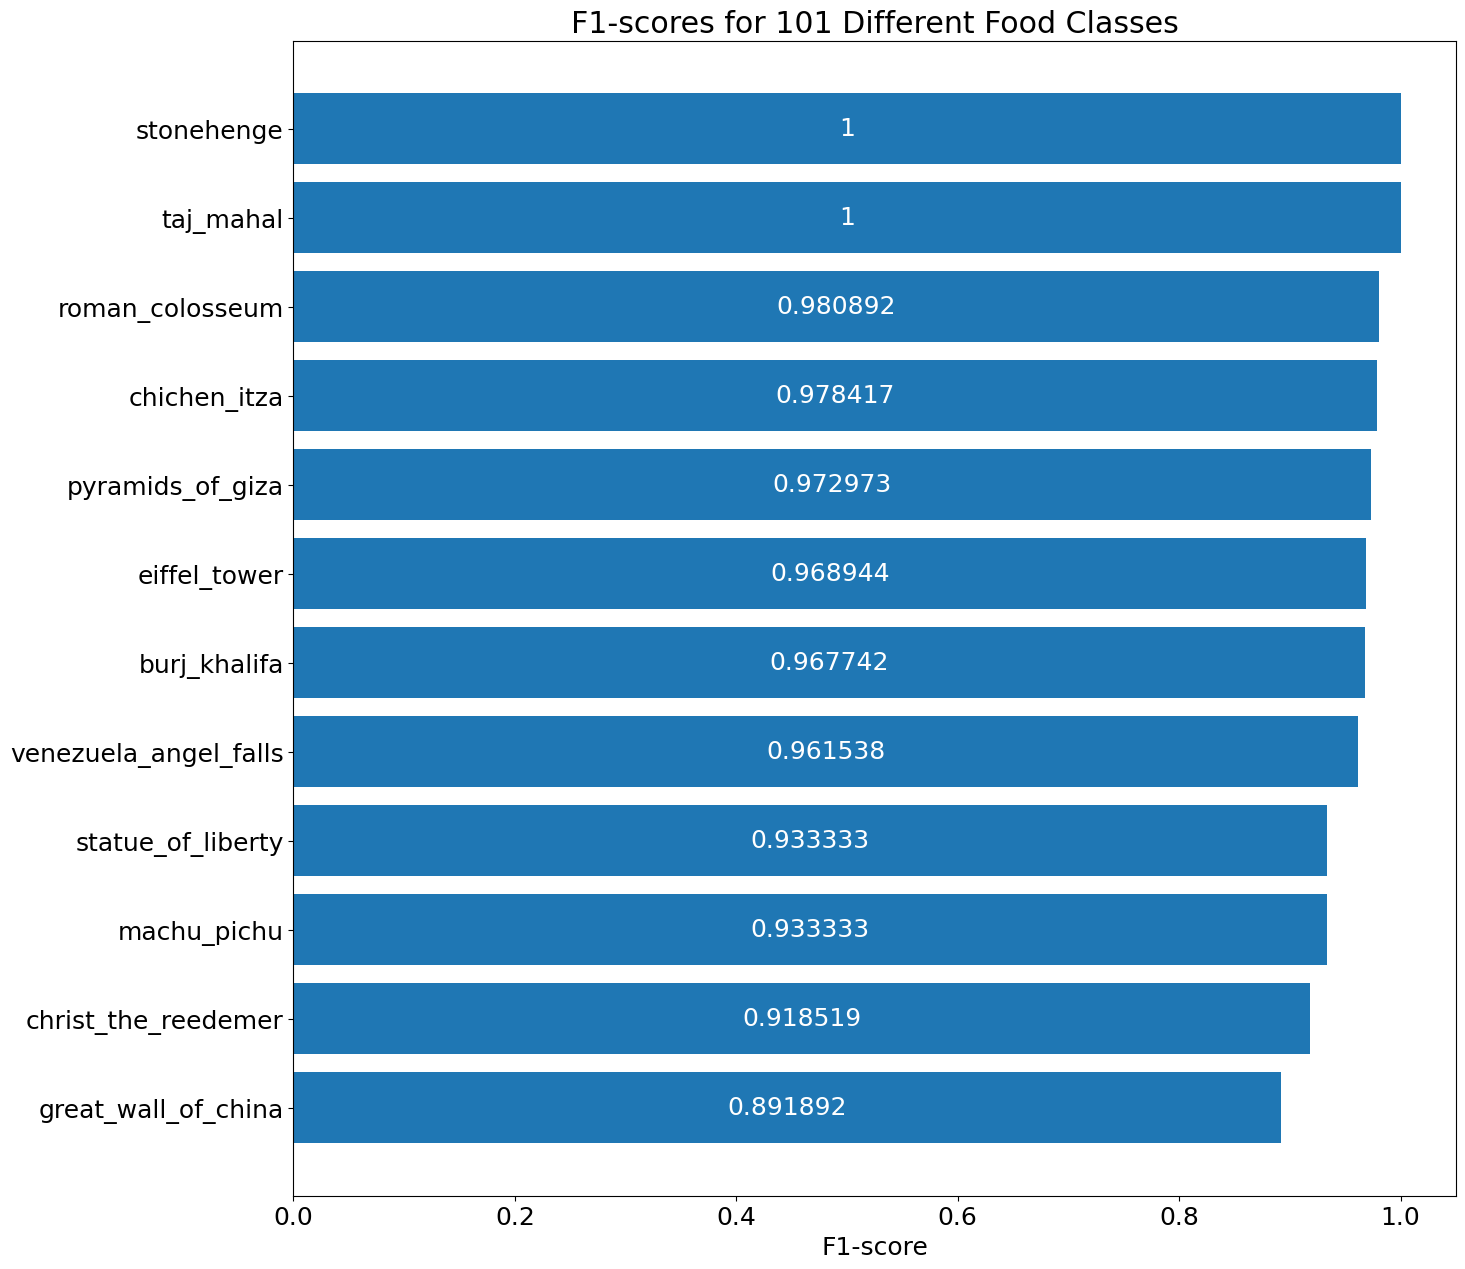

In [63]:
plot_f1_scores_on_every_class_name(f1_scores=f1_scores, figsize=(15, 15))

# Make random predictions

In [64]:
def load_and_prep_image(filename, img_shape=224, scale=True):
    """
    Reads in an image from filename, turns it into a tensor and reshapes into
    (224, 224, 3).

    Parameters
    ----------
    filename (str): string filename of target image
    img_shape (int): size to resize target image to, default 224
    scale (bool): whether to scale pixel values to range(0, 1), default True
    """
    # Read in the image
    img = tf.io.read_file(filename)
    # Decode it into a tensor
    img = tf.image.decode_jpeg(img, channels=3)
    # Resize the image
    img = tf.image.resize(img, [img_shape, img_shape])
    if scale:
        # Rescale the image (get all values between 0 and 1)
        return img/255.
    else:
        return img


In [67]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf

def make_random_prediction(class_names, test_dir, qty: int = 3, figsize =(17, 10), fontsize: int = 12, image_shape=400):
    plt.figure(figsize=figsize)
    for i in range(qty):
        # Choose random image from random class
        class_name = random.choice(class_names)
        filepath = os.path.join(test_dir, class_name, random.choice(os.listdir(os.path.join(test_dir, class_name))))
        
        # Load and preprocess the image
        img = load_and_prep_image(filepath, scale=False, img_shape=image_shape)  # img_shape=400
        print("filepath:", filepath)
        print("before:", img.shape)
        
        # Add batch dimension
        img_expanded = tf.expand_dims(img, axis=0)
        print("after:", img_expanded.shape)
        
        # Predict
        pred_prob = model_1.predict(img_expanded)
        pred_class = class_names[pred_prob.argmax()]
        
        # Plot
        plt.subplot(1, qty, i+1)
        plt.imshow(img / 255.)  # normalize for display
        title_color = "g" if class_name == pred_class else "r"
        plt.title(f"actual: {class_name}, pred: {pred_class}, prob: {pred_prob.max():.2f}", 
                  c=title_color, fontdict={'fontsize': fontsize})
        plt.axis("off")

    plt.show()

filepath: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\val\christ_the_reedemer\1a9859d5d6.jpg
before: (400, 400, 3)
after: (1, 400, 400, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step
filepath: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\val\statue_of_liberty\1b66d824e2.jpg
before: (400, 400, 3)
after: (1, 400, 400, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step
filepath: C:\Users\anug2\Downloads\CV Project Assignment\dataset_splitted\val\christ_the_reedemer\21b90247f7.jpg
before: (400, 400, 3)
after: (1, 400, 400, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step


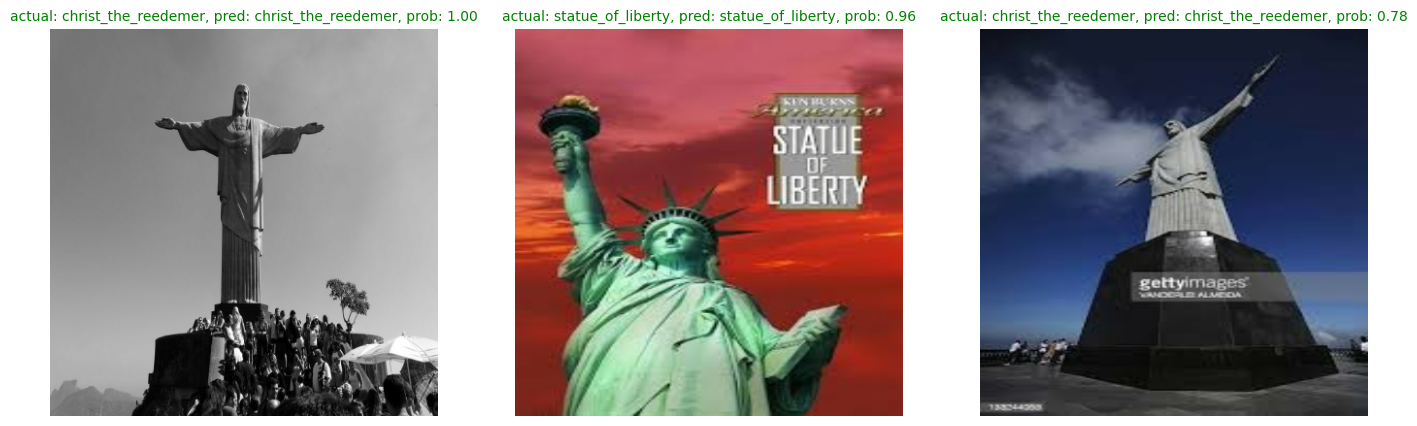

In [71]:
make_random_prediction(class_names, test_dir=TEST_DIR, fontsize=10, qty=3, image_shape=400)